# 04. Binary Action Classification Using k-Nearest Neighbors (kNN)
**Project:** Analysis of Physical Actions Using EMG Signal Classification  
**Target Environment:** Google Colab / Jupyter Notebook  

---

### Notebook Overview
In this notebook, we perform binary classification on surface EMG features using the **$k$-Nearest Neighbors ($k$-NN)** algorithm.

### Two Classification Scenarios
1. **Scenario A — Normal vs. Aggressive Classification (Full Dataset, 1,200 Samples):**
   - Distinguish general **Normal movements (Class 0)** from **Aggressive actions (Class 1)** across all 4 subjects and 20 classes.
2. **Scenario B — Pairwise Two-Class Classification (Assignment Specification, 120 Samples):**
   - Classify between any two specific classes (e.g., 1 Normal action like *Bowing* vs. 1 Aggressive action like *Elbowing*).
   - Sample size: $4 \text{ subjects} \times 2 \text{ classes} \times 15 \text{ trials} = 120$ samples.

### Preventing Data Leakage
- To prevent data leakage, we construct a scikit-learn `Pipeline`:
  ```python
  pipeline = Pipeline([
      ('scaler', StandardScaler()),
      ('knn', KNeighborsClassifier(n_neighbors=k))
  ])
  ```
  This ensures `StandardScaler` is fitted **exclusively on each training fold** during cross-validation.

In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

print("Machine learning environment initialized.")

Machine learning environment initialized.


---
## 1. Google Drive Mounting & Dataset Setup

If your dataset is stored in Google Drive (e.g., from the shared link `https://drive.google.com/drive/folders/1qRhw4-W7QCJVh7oLJjysbSUlKHDFT-sB`):

1. **Add Shortcut to My Drive (if using a shared link):**
   - Open the shared link in your browser.
   - Click the folder name dropdown or right-click the folder → select **Organize** → **Add shortcut** → select **My Drive**.
2. **Mount Google Drive:**
   - Running the code cell below executes `drive.mount('/content/drive')`. Colab will prompt you to authorize access.
3. **Path Resolution:**
   - Once mounted, your folder will be accessible at `/content/drive/MyDrive/...`.
   - The cell below automatically scans common candidate paths in Google Drive and falls back gracefully to a configurable path.

In [2]:
# Step 2: Mount Google Drive and Configure Dataset Path

# Mount Google Drive if running inside Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive successfully mounted at /content/drive")
except ImportError:
    print("Not running in Google Colab; using local file system.")

# Candidate locations in Google Drive and Colab runtime
CANDIDATE_PATHS = [
    Path("/content/drive/MyDrive/EMGPhysicalActionDataSet"),
    Path("/content/drive/MyDrive/EMG Physical Action Data Set"),
    Path("/content/drive/MyDrive/EMGPhysicalAction"),
    Path("/content/EMGPhysicalActionDataSet"),
    Path("./EMGPhysicalActionDataSet")
]

# Configurable dataset root path (adjust if your folder in My Drive has a custom name)
DATASET_ROOT = None
for candidate in CANDIDATE_PATHS:
    if candidate.exists() and any(candidate.glob("sub*")):
        DATASET_ROOT = candidate
        break

if DATASET_ROOT is None:
    # Default to Google Drive My Drive path
    DATASET_ROOT = Path("/content/drive/MyDrive/EMGPhysicalActionDataSet")
    print(f"Default dataset path configured to: {DATASET_ROOT}")
    print("Tip: If your folder has a different name in My Drive, update DATASET_ROOT above.")
else:
    print(f"Verified dataset root directory located at: {DATASET_ROOT}")

Mounted at /content/drive
Google Drive successfully mounted at /content/drive
Verified dataset root directory located at: /content/drive/MyDrive/EMGPhysicalActionDataSet


---
## 2. Experimental Parameters & Classes

In [3]:
# Step 3: Parameters and Class Mappings

N_SEG = 4
EXPECTED_TRIALS_PER_FILE = 15
EXPECTED_CHANNELS = 8
RANDOM_STATE = 42

NORMAL_ACTIONS = [
    "Bowing", "Clapping", "Handshaking", "Hugging", "Jumping",
    "Running", "Seating", "Standing", "Walking", "Waving"
]

AGGRESSIVE_ACTIONS = [
    "Elbowing", "Frontkicking", "Hamering", "Headering", "Kneeing",
    "Pulling", "Punching", "Pushing", "Sidekicking", "Slapping"
]

ALL_ACTIONS = NORMAL_ACTIONS + AGGRESSIVE_ACTIONS
ACTION_TO_MULTICLASS = {action: idx for idx, action in enumerate(ALL_ACTIONS, start=1)}
ACTION_TO_BINARY = {action: (0 if action in NORMAL_ACTIONS else 1) for action in ALL_ACTIONS}

print(f"Random state: {RANDOM_STATE} (for reproducible CV folds)")
print(f"Features per trial: 16 x {N_SEG} = {16 * N_SEG}")

Random state: 42 (for reproducible CV folds)
Features per trial: 16 x 4 = 64


---
## 3. Self-Contained Data Loading and Feature Generation

In [4]:
# Step 4: Loading and Feature Extraction Pipeline

def read_emg_file(file_path: Path) -> np.ndarray:
    file_path = Path(file_path)
    if not file_path.is_file():
        raise FileNotFoundError(f"File not found: {file_path}")
    try:
        df = pd.read_csv(file_path, sep=r'[\s,]+', engine='python', header=None).dropna(how='all', axis=1)
        data = df.to_numpy(dtype=np.float64)
    except Exception as e:
        raise ValueError(f"Error parsing {file_path.name}: {e}")
    if data.ndim != 2 or data.shape[1] != EXPECTED_CHANNELS:
        raise ValueError(f"Expected {EXPECTED_CHANNELS} channels in {file_path.name}")
    return data


def find_action_file(subject_dir: Path, action_name: str) -> Path:
    subject_dir = Path(subject_dir)
    variants = [action_name.lower()]
    if action_name.lower() == "hamering":
        variants.append("hammering")
    elif action_name.lower() == "hammering":
        variants.append("hamering")

    search_dirs = [
        subject_dir / "txt", subject_dir / "log",
        subject_dir / "Aggressive" / "txt", subject_dir / "Normal" / "txt",
        subject_dir / "Aggressive" / "log", subject_dir / "Normal" / "log",
        subject_dir
    ]
    for s_dir in search_dirs:
        if s_dir.exists():
            for f in s_dir.rglob("*"):
                if f.is_file() and f.suffix.lower() in [".txt", ".log", ".csv"]:
                    stem = f.stem.lower()
                    for v in variants:
                        if stem == v or stem == f"{v}_data" or stem.startswith(f"{v}_") or stem.endswith(f"_{v}"):
                            return f
    return None


def segment_recording_into_trials(signal_data: np.ndarray, num_trials: int = 15) -> list:
    total_samples = signal_data.shape[0]
    trial_length = total_samples // num_trials
    return [signal_data[i * trial_length : (i + 1) * trial_length, :] for i in range(num_trials)]


def extract_trial_features(trial_signal: np.ndarray, n_seg: int = 4) -> np.ndarray:
    trial_samples, n_channels = trial_signal.shape
    seg_length = trial_samples // n_seg
    features = []
    for ch in range(n_channels):
        channel_data = trial_signal[:, ch]
        for s in range(n_seg):
            segment = channel_data[s * seg_length : (s + 1) * seg_length]
            features.append(np.mean(segment))
            features.append(np.var(segment, ddof=0))
    return np.array(features, dtype=np.float64)


def load_dataset(dataset_root: Path, n_seg: int = 4, num_trials: int = 15):
    if not dataset_root.exists():
        raise FileNotFoundError(f"Dataset root does not exist: {dataset_root}")
    subject_dirs = sorted([d for d in dataset_root.iterdir() if d.is_dir() and d.name.lower().startswith("sub")], key=lambda d: d.name.lower())
    if not subject_dirs:
        raise FileNotFoundError(f"No subject directories in {dataset_root}")

    X_list, y_bin_list, y_multi_list, meta = [], [], [], []
    for s_dir in subject_dirs:
        for action in ALL_ACTIONS:
            f_path = find_action_file(s_dir, action)
            if f_path is None:
                raise FileNotFoundError(f"Missing file for '{action}' in {s_dir.name}")
            raw = read_emg_file(f_path)
            trials = segment_recording_into_trials(raw, num_trials=num_trials)
            b_lbl = ACTION_TO_BINARY[action]
            m_lbl = ACTION_TO_MULTICLASS[action]
            for t_idx, tr in enumerate(trials, start=1):
                X_list.append(extract_trial_features(tr, n_seg=n_seg))
                y_bin_list.append(b_lbl)
                y_multi_list.append(m_lbl)
                meta.append({"Subject": s_dir.name, "Action": action, "Trial": t_idx, "Binary_Label": b_lbl, "Multiclass_Label": m_lbl})

    return np.vstack(X_list), np.array(y_bin_list, dtype=np.int64), np.array(y_multi_list, dtype=np.int64), pd.DataFrame(meta)

X, y_binary, y_multi, metadata_df = load_dataset(DATASET_ROOT, n_seg=N_SEG, num_trials=EXPECTED_TRIALS_PER_FILE)
print(f"Loaded dataset: X shape = {X.shape}, y_binary shape = {y_binary.shape}")
print(f"Class counts: Normal (0) = {np.sum(y_binary == 0)}, Aggressive (1) = {np.sum(y_binary == 1)}")

Loaded dataset: X shape = (1200, 64), y_binary shape = (1200,)
Class counts: Normal (0) = 600, Aggressive (1) = 600


---
## 4. Leakage-Free Pipeline Construction

In [5]:
# Step 5: Construct Pipeline and Cross-Validation Splitter

def build_knn_pipeline(n_neighbors: int = 5, metric: str = 'euclidean') -> Pipeline:
    """Constructs leakage-free scaling and kNN pipeline."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric))
    ])

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Pipeline configured with StandardScaler and KNeighborsClassifier(n_neighbors=5).")
print(f"Cross-validation: 5-Fold Stratified (seed={RANDOM_STATE})")

Pipeline configured with StandardScaler and KNeighborsClassifier(n_neighbors=5).
Cross-validation: 5-Fold Stratified (seed=42)


---
## 5. Scenario A: Normal vs. Aggressive Classification (1,200 Samples)

In [6]:
# Step 6: Evaluate Normal vs. Aggressive Cross-Validation Performance

scoring = ['accuracy', 'precision', 'recall', 'f1']
pipeline_default = build_knn_pipeline(n_neighbors=5)

cv_results = cross_validate(
    pipeline_default, X, y_binary, cv=cv_5fold, scoring=scoring, return_train_score=False
)

print("--- 5-Fold Cross-Validation Performance (Normal vs. Aggressive) ---")
print(f"Accuracy:  {np.mean(cv_results['test_accuracy']):.4f} +/- {np.std(cv_results['test_accuracy']):.4f}")
print(f"Precision: {np.mean(cv_results['test_precision']):.4f} +/- {np.std(cv_results['test_precision']):.4f}")
print(f"Recall:    {np.mean(cv_results['test_recall']):.4f} +/- {np.std(cv_results['test_recall']):.4f}")
print(f"F1-Score:  {np.mean(cv_results['test_f1']):.4f} +/- {np.std(cv_results['test_f1']):.4f}")

y_pred = cross_val_predict(pipeline_default, X, y_binary, cv=cv_5fold)
y_proba = cross_val_predict(pipeline_default, X, y_binary, cv=cv_5fold, method='predict_proba')[:, 1]

print("\nClassification Report:")
print(classification_report(y_binary, y_pred, target_names=["Normal (0)", "Aggressive (1)"]))

--- 5-Fold Cross-Validation Performance (Normal vs. Aggressive) ---
Accuracy:  0.8408 +/- 0.0284
Precision: 0.8621 +/- 0.0310
Recall:    0.8117 +/- 0.0314
F1-Score:  0.8360 +/- 0.0296

Classification Report:
                precision    recall  f1-score   support

    Normal (0)       0.82      0.87      0.85       600
Aggressive (1)       0.86      0.81      0.84       600

      accuracy                           0.84      1200
     macro avg       0.84      0.84      0.84      1200
  weighted avg       0.84      0.84      0.84      1200



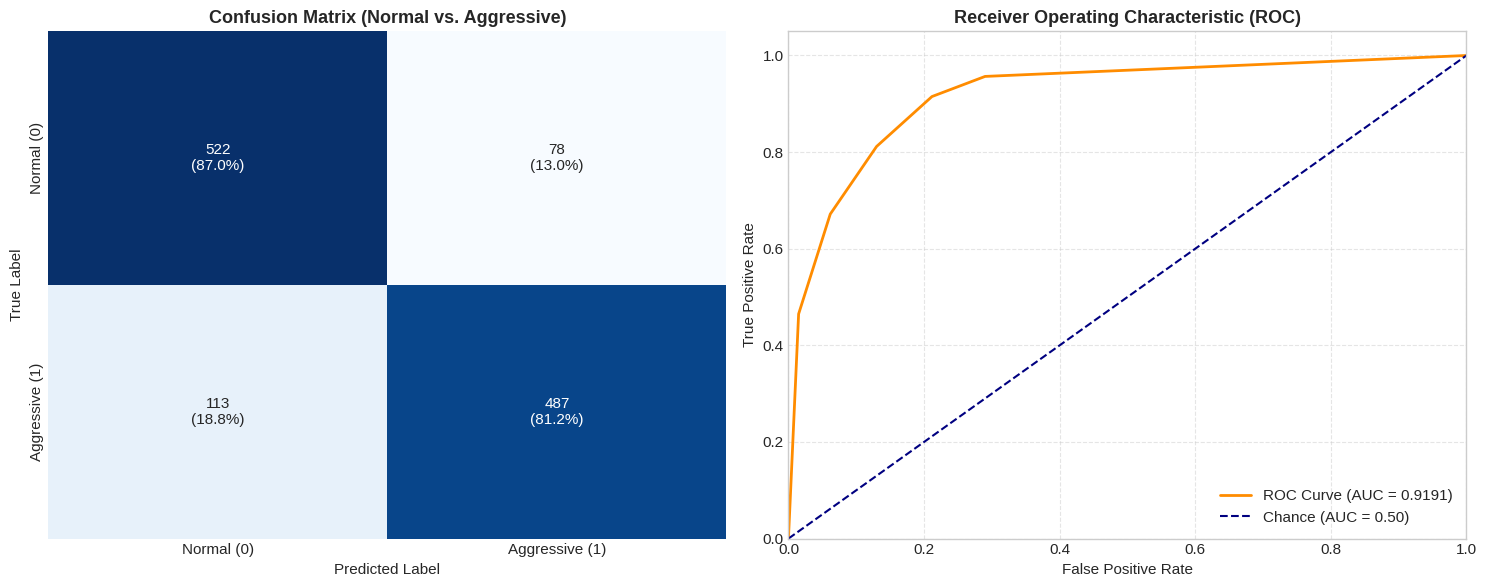

In [7]:
# Step 7: Plot Confusion Matrix and ROC Curve

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Confusion Matrix
cm = confusion_matrix(y_binary, y_pred)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
annot = np.array([f"{count}\n({pct:.1f}%)" for count, pct in zip(cm.flatten(), cm_pct.flatten())]).reshape(2, 2)

sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=["Normal (0)", "Aggressive (1)"], yticklabels=["Normal (0)", "Aggressive (1)"])
axes[0].set_title("Confusion Matrix (Normal vs. Aggressive)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Label", fontsize=11)
axes[0].set_ylabel("True Label", fontsize=11)

# ROC Curve
fpr, tpr, _ = roc_curve(y_binary, y_proba)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f"ROC Curve (AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label="Chance (AUC = 0.50)")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("False Positive Rate", fontsize=11)
axes[1].set_ylabel("True Positive Rate", fontsize=11)
axes[1].set_title("Receiver Operating Characteristic (ROC)", fontsize=13, fontweight='bold')
axes[1].legend(loc="lower right", fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 6. Hyperparameter Sensitivity: Exploring Neighborhood Size ($k$)

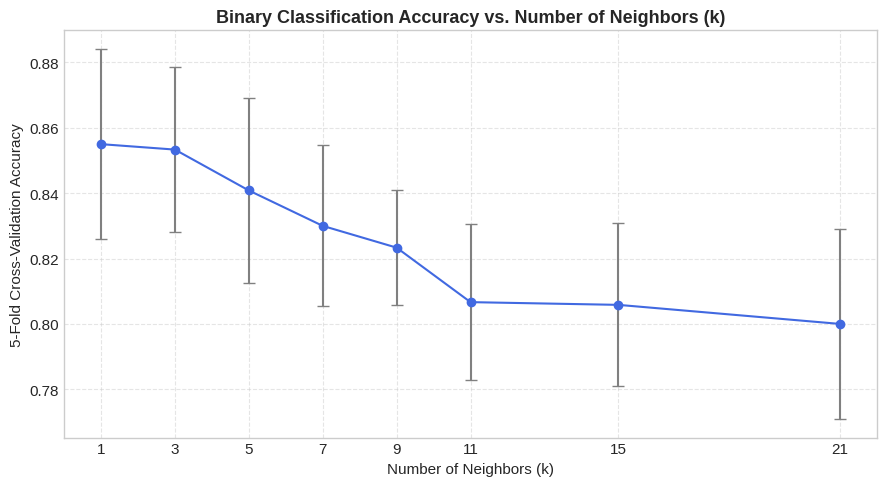

Optimal k: 1 with Accuracy: 0.8550 +/- 0.0292


In [8]:
# Step 8: Hyperparameter Tuning over k

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
k_mean_acc = []
k_std_acc = []

for k in k_values:
    pipe = build_knn_pipeline(n_neighbors=k)
    scores = cross_val_score(pipe, X, y_binary, cv=cv_5fold, scoring='accuracy')
    k_mean_acc.append(np.mean(scores))
    k_std_acc.append(np.std(scores))

plt.figure(figsize=(9, 5))
plt.errorbar(k_values, k_mean_acc, yerr=k_std_acc, fmt='-o', color='royalblue', ecolor='gray', elinewidth=1.5, capsize=4)
plt.title("Binary Classification Accuracy vs. Number of Neighbors (k)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Neighbors (k)", fontsize=11)
plt.ylabel("5-Fold Cross-Validation Accuracy", fontsize=11)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

best_k_idx = np.argmax(k_mean_acc)
print(f"Optimal k: {k_values[best_k_idx]} with Accuracy: {k_mean_acc[best_k_idx]:.4f} +/- {k_std_acc[best_k_idx]:.4f}")

---
## 7. Scenario B: Pairwise Two-Class Classification (Assignment Task: 120 Samples)

Sample count: $4 \text{ subjects} \times 2 \text{ classes} \times 15 \text{ trials} = 120$ samples.

--- Pairwise Dataset: Bowing vs. Elbowing ---
X_pair shape: (120, 64) (Expected: 120, 64)

Pairwise 5-Fold Cross-Validation Accuracy: 0.8417 +/- 0.0890


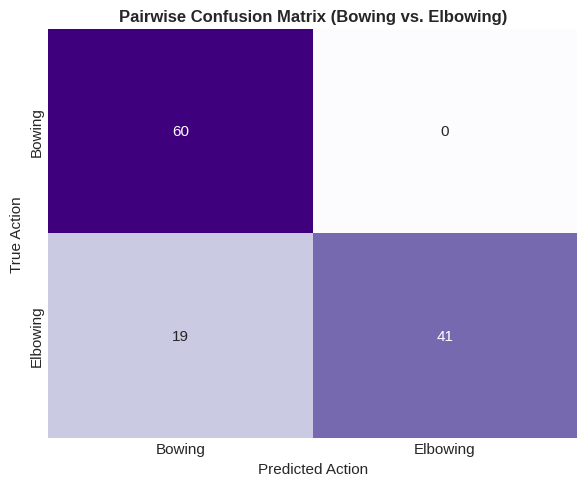

In [9]:
# Step 9: Pairwise Binary Classification (e.g., Bowing vs. Elbowing, 120 Samples)

pair_class_1 = "Bowing"
pair_class_2 = "Elbowing"

lbl_1 = ACTION_TO_MULTICLASS[pair_class_1]
lbl_2 = ACTION_TO_MULTICLASS[pair_class_2]

pair_mask = np.isin(y_multi, [lbl_1, lbl_2])
X_pair = X[pair_mask]
y_pair = (y_multi[pair_mask] == lbl_2).astype(np.int64)

print(f"--- Pairwise Dataset: {pair_class_1} vs. {pair_class_2} ---")
print(f"X_pair shape: {X_pair.shape} (Expected: 120, {X.shape[1]})")

pair_pipeline = build_knn_pipeline(n_neighbors=5)
pair_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pair_scores = cross_val_score(pair_pipeline, X_pair, y_pair, cv=pair_cv, scoring='accuracy')

print(f"\nPairwise 5-Fold Cross-Validation Accuracy: {np.mean(pair_scores):.4f} +/- {np.std(pair_scores):.4f}")

y_pair_pred = cross_val_predict(pair_pipeline, X_pair, y_pair, cv=pair_cv)
cm_pair = confusion_matrix(y_pair, y_pair_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_pair, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=[pair_class_1, pair_class_2], yticklabels=[pair_class_1, pair_class_2])
plt.title(f"Pairwise Confusion Matrix ({pair_class_1} vs. {pair_class_2})", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Action")
plt.ylabel("True Action")
plt.tight_layout()
plt.show()

---
## 8. Key Findings and Next Steps

1. **High Separability:** Distinguishing Normal from Aggressive actions achieves strong classification accuracy.
2. **Leakage Prevention:** Standardizing within cross-validation folds ensures unbiased performance estimates.
3. **Next Step:** In `05_multiclass_analysis.ipynb`, we evaluate multiclass classification for $M = 2$ through $19$ classes.